# Benchmark de latencia

Mide ms/frame y FPS de cada detector y del **sistema completo** (detector + clasificador de recortes), con batch 1, sobre imágenes reales de test precargadas en memoria (sin disco), después de un warm-up.

- **CPU** siempre; **GPU** si hay. El argumento de despliegue real (una cámara, un equipo edge) es CPU: correr el notebook en local para CPU y en Colab/Kaggle para GPU. Cada corrida agrega o reemplaza sus filas en `results/benchmark.csv` (clave: modelo, imgsz, device).
- **Sistema:** a cada imagen, detector → recortes de las cajas con `conf > τ` → clasificador. Se mide con la cantidad real de cajas por frame, que es lo que va a pagar la cámara.
- Con `master.csv` cargado, cruza mAP50 de test contra ms en CPU: el trade-off capacidad / latencia (conclusión 1 del paper).

Fuera de local hay que subir `recortes.py` a la sesión.

In [1]:
import os
import platform
import random
import subprocess
import sys
import time
from datetime import date
from pathlib import Path

# Kaggle se reconoce por su variable de entorno, no por /kaggle/input: Colab también puede tener esa carpeta
IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
# Colab: el módulo ya cargado, o las variables de entorno que define el runtime
IN_COLAB = "google.colab" in sys.modules or any(k.startswith("COLAB_") for k in os.environ)
PLATFORM = "colab" if IN_COLAB else "kaggle" if IN_KAGGLE else "local"
if PLATFORM != "local":
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.4.157", "kagglehub"], check=True)
DRIVE_OK = False
if PLATFORM == "colab":
    # Drive permite retomar un run en otra sesión. Si no se puede montar (Colab desde VS Code,
    # ventana de autorización bloqueada, varias cuentas de Google abiertas), se sigue en el disco
    # de la sesión: funciona igual, pero hay que bajar el zip del final antes de cerrar.
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE_OK = True
    except Exception as e:
        print(f"[!] No se pudo montar Drive ({e}). Se guarda en /content/incendios-tp: "
              "bajar el zip del final antes de cerrar la sesión.")

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import ultralytics
from tqdm.auto import tqdm
from ultralytics import YOLO

import recortes

WORK_DIR = {"kaggle": Path("/kaggle/working"), "colab": Path("/content/drive/MyDrive/incendios-tp" if DRIVE_OK else "/content/incendios-tp"),
            "local": Path.cwd()}[PLATFORM]
RUNS_DIR, RESULTS_DIR, FIG_DIR = WORK_DIR / "runs", WORK_DIR / "results", WORK_DIR / "figures"
for d in (RESULTS_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

CPU_NAME = platform.processor() or platform.machine()
GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
print(f"Plataforma: {PLATFORM} | CPU: {CPU_NAME} ({torch.get_num_threads()} hilos torch) | GPU: {GPU_NAME}")

Plataforma: local | CPU: Intel64 Family 6 Model 186 Stepping 3, GenuineIntel (10 hilos torch) | GPU: None


## 1. Configuración

`RUNS`: detectores a medir (los que tengan `best.pt` en `runs/`; los que falten se saltean). `N_WARMUP = 100` como pide el plan; `N_MEDIR` imágenes medidas por modelo y device.

In [2]:
RUNS = {  # run → imgsz
    "yolo11n_640_neg_s42": 640,
    "yolo11s_640_neg_s42": 640,
    "yolo11m_640_neg_s42": 640,
    "yolo11n_960_neg_s42": 960,
    "yolo11s_960_neg_s42": 960,
    "yolo11n_640_noneg_s42": 640,
}
SISTEMA_RUN = "yolo11n_640_neg_s42"   # detector del sistema, para medir detector + clasificador
CLF_WEIGHTS = RUNS_DIR / "clasificador" / "weights" / "best.pt"
CLF_IMGSZ = 224
TAU = 0.40
CONF_MIN = 0.05

N_WARMUP = 100
N_MEDIR = 300
SEED = 42
SMOKE_TEST = False   # True: pocas imágenes y pesos de COCO si no hay runs

if SMOKE_TEST:
    N_WARMUP, N_MEDIR = 5, 20

DEVICES = ["cpu"] + ([0] if GPU_NAME else [])
detectores = {r: (RUNS_DIR / r / "weights" / "best.pt", imgsz) for r, imgsz in RUNS.items()
              if (RUNS_DIR / r / "weights" / "best.pt").exists()}
if not detectores and SMOKE_TEST:
    detectores = {"coco_yolo11n": ("yolo11n.pt", 640)}
    SISTEMA_RUN = "coco_yolo11n"
print("Detectores a medir:", list(detectores) or "ninguno (entrenar con train.ipynb)")

Detectores a medir: ['yolo11n_640_neg_s42', 'yolo11m_640_neg_s42', 'yolo11n_960_neg_s42', 'yolo11n_640_noneg_s42']


In [3]:
def find_split_root(base: Path) -> Path | None:
    for train_dir in base.rglob("train"):
        root = train_dir.parent
        if all((root / s / "images").is_dir() for s in ("train", "val", "test")):
            return root
    return None

if PLATFORM == "kaggle":
    SPLIT_ROOT = find_split_root(Path("/kaggle/input"))
elif PLATFORM == "colab":
    import kagglehub
    SPLIT_ROOT = find_split_root(Path(kagglehub.dataset_download("sayedgamal99/smoke-fire-detection-yolo")))
else:
    SPLIT_ROOT = find_split_root(Path.cwd() / "data")

# Imágenes reales de test, con su mezcla de resoluciones, precargadas para no medir disco
rutas = sorted((SPLIT_ROOT / "test" / "images").iterdir())
muestra = random.Random(SEED).sample(rutas, N_WARMUP + N_MEDIR)
imgs = [cv2.imread(str(p)) for p in tqdm(muestra, desc="precargando")]
print(f"{len(imgs)} imágenes ({N_WARMUP} warm-up + {N_MEDIR} medidas)")

precargando:   0%|          | 0/400 [00:00<?, ?it/s]

400 imágenes (100 warm-up + 300 medidas)


## 2. Detector solo

Por imagen: `ms_total` es el tiempo de pared de `predict` (preprocesamiento + inferencia + NMS), que es lo que ve el sistema; `ms_pre`, `ms_inf` y `ms_post` son el desglose de Ultralytics. En GPU se sincroniza antes de cortar el reloj. Se reportan media, p50 y p95: la p95 es la que importa para un sistema en tiempo real.

In [4]:
def sync(device):
    if device != "cpu":
        torch.cuda.synchronize()

def medir_detector(pesos, imgsz: int, device) -> pd.DataFrame:
    modelo = YOLO(pesos)
    for img in imgs[:N_WARMUP]:
        modelo.predict(img, imgsz=imgsz, conf=CONF_MIN, device=device, verbose=False)
    filas = []
    for img in imgs[N_WARMUP:]:
        sync(device)
        t0 = time.perf_counter()
        r = modelo.predict(img, imgsz=imgsz, conf=CONF_MIN, device=device, verbose=False)[0]
        sync(device)
        filas.append({"ms_total": (time.perf_counter() - t0) * 1000, "ms_pre": r.speed["preprocess"],
                      "ms_inf": r.speed["inference"], "ms_post": r.speed["postprocess"]})
    return pd.DataFrame(filas)

def resumen(nombre: str, tipo: str, imgsz: int, device, t: pd.DataFrame, extra: dict | None = None) -> dict:
    return {
        "modelo": nombre, "tipo": tipo, "imgsz": imgsz,
        "device": "cpu" if device == "cpu" else "gpu", "hardware": CPU_NAME if device == "cpu" else GPU_NAME,
        "ms_media": t["ms_total"].mean(), "ms_p50": t["ms_total"].median(), "ms_p95": t["ms_total"].quantile(0.95),
        "fps": 1000 / t["ms_total"].mean(),
        **{c: t[c].mean() for c in t.columns if c != "ms_total"},
        **(extra or {}),
        "plataforma": PLATFORM, "ultralytics": ultralytics.__version__, "fecha": date.today().isoformat(),
    }

filas = []
for (run, (pesos, imgsz)), device in [(d, dev) for d in detectores.items() for dev in DEVICES]:
    t = medir_detector(pesos, imgsz, device)
    filas.append(resumen(run, "detector", imgsz, device, t))
    print(f"{run} @ {filas[-1]['device']}: {filas[-1]['ms_media']:.1f} ms (p95 {filas[-1]['ms_p95']:.1f}) | {filas[-1]['fps']:.1f} FPS")

yolo11n_640_neg_s42 @ cpu: 56.0 ms (p95 65.4) | 17.9 FPS
yolo11m_640_neg_s42 @ cpu: 299.3 ms (p95 353.4) | 3.3 FPS
yolo11n_960_neg_s42 @ cpu: 92.3 ms (p95 112.0) | 10.8 FPS
yolo11n_640_noneg_s42 @ cpu: 55.1 ms (p95 64.3) | 18.2 FPS


## 3. Sistema completo: detector + clasificador de recortes

Por imagen: detección, recorte de las cajas con `conf > τ` (como en `demo.py`) y clasificación de todos los recortes en un solo batch. `n_recortes` es el promedio de cajas clasificadas por imagen: el costo del clasificador escala con eso.

In [5]:
def medir_sistema(det_pesos, imgsz: int, clf_pesos, device) -> pd.DataFrame:
    det, clf = YOLO(det_pesos), YOLO(clf_pesos)
    def paso(img):
        r = det.predict(img, imgsz=imgsz, conf=CONF_MIN, device=device, verbose=False)[0]
        cajas = [b for b, c in zip(r.boxes.xyxy.tolist(), r.boxes.conf.tolist()) if c > TAU]
        if cajas:
            clf.predict([recortes.recortar(img, *b) for b in cajas], imgsz=CLF_IMGSZ, device=device, verbose=False)
        return len(cajas)
    for img in imgs[:N_WARMUP]:
        paso(img)
    filas = []
    for img in imgs[N_WARMUP:]:
        sync(device)
        t0 = time.perf_counter()
        n = paso(img)
        sync(device)
        filas.append({"ms_total": (time.perf_counter() - t0) * 1000, "n_recortes": n})
    return pd.DataFrame(filas)

clf_pesos = CLF_WEIGHTS if CLF_WEIGHTS.exists() else ("yolo11n-cls.pt" if SMOKE_TEST else None)
if clf_pesos and SISTEMA_RUN in detectores:
    det_pesos, imgsz = detectores[SISTEMA_RUN]
    for device in DEVICES:
        t = medir_sistema(det_pesos, imgsz, clf_pesos, device)
        filas.append(resumen(f"{SISTEMA_RUN}+clasificador", "sistema", imgsz, device, t,
                             {"tau": TAU, "n_recortes": t["n_recortes"].mean()}))
        print(f"sistema @ {filas[-1]['device']}: {filas[-1]['ms_media']:.1f} ms | {filas[-1]['n_recortes']:.2f} recortes/imagen")
else:
    print("Sin clasificador o sin el detector del sistema: se mide solo el detector.")

sistema @ cpu: 62.9 ms | 0.83 recortes/imagen


In [6]:
BENCH = RESULTS_DIR / ("benchmark_smoke.csv" if SMOKE_TEST else "benchmark.csv")
nuevas = pd.DataFrame(filas)
if BENCH.exists() and len(nuevas):
    previas = pd.read_csv(BENCH)
    clave = ["modelo", "imgsz", "device"]
    previas = previas[~previas.set_index(clave).index.isin(nuevas.set_index(clave).index)]
    nuevas = pd.concat([previas, nuevas], ignore_index=True)
nuevas.to_csv(BENCH, index=False)
print("Actualizado:", BENCH)
nuevas.round(2)

Actualizado: c:\Proyectos\CV2\detección_incendios\results\benchmark.csv


,modelo,tipo,imgsz,device,hardware,ms_media,ms_p50,ms_p95,fps,ms_pre,ms_inf,ms_post,plataforma,ultralytics,fecha,n_recortes,tau
0,yolo11n_640_neg_s42,detector,640,cpu,"Intel64 Family 6 Model 186 Stepping 3, Genuine...",55.98,56.08,65.45,17.86,1.74,52.71,1.08,local,8.4.157,2026-10-03,NaN,NaN
1,yolo11m_640_neg_s42,detector,640,cpu,"Intel64 Family 6 Model 186 Stepping 3, Genuine...",299.29,291.00,353.43,3.34,1.80,294.94,1.08,local,8.4.157,2026-10-03,NaN,NaN
2,yolo11n_960_neg_s42,detector,960,cpu,"Intel64 Family 6 Model 186 Stepping 3, Genuine...",92.25,90.28,111.99,10.84,4.98,85.66,1.15,local,8.4.157,2026-10-03,NaN,NaN
3,yolo11n_640_noneg_s42,detector,640,cpu,"Intel64 Family 6 Model 186 Stepping 3, Genuine...",55.06,55.51,64.28,18.16,1.81,51.54,1.20,local,8.4.157,2026-10-03,NaN,NaN
4,yolo11n_640_neg_s42+clasificador,sistema,640,cpu,"Intel64 Family 6 Model 186 Stepping 3, Genuine...",62.89,58.84,84.10,15.90,NaN,NaN,NaN,local,8.4.157,2026-10-03,0.83,0.4


## 4. Trade-off capacidad / latencia

mAP50 de test (de `master.csv`) contra ms/frame en CPU, un punto por detector. Arriba a la izquierda es mejor.

,modelo,imgsz,ms_media,ms_p95,fps,test_mAP50,test_mAP50_fire,test_mAP50_smoke
0,yolo11n_640_neg_s42,640,55.980,65.447,17.864,0.759,0.698,0.820
1,yolo11m_640_neg_s42,640,299.293,353.433,3.341,0.779,0.719,0.838
2,yolo11n_960_neg_s42,960,92.253,111.989,10.840,0.773,0.716,0.829
3,yolo11n_640_noneg_s42,640,55.062,64.283,18.161,0.699,0.670,0.727


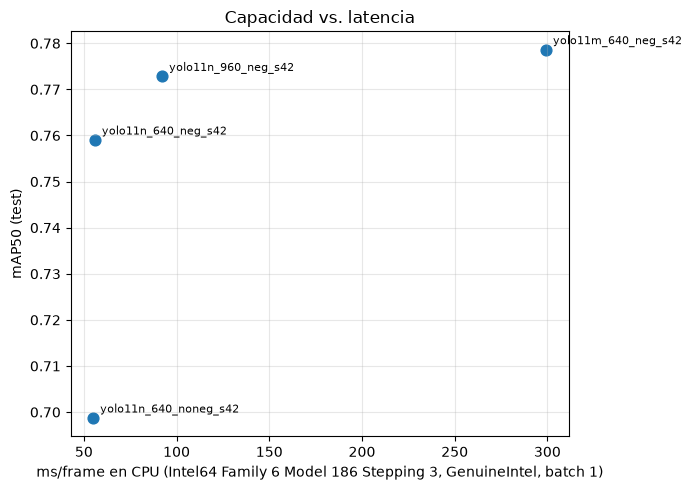

In [7]:
master_path = RESULTS_DIR / "master.csv"
cpu = nuevas[(nuevas["device"] == "cpu") & (nuevas["tipo"] == "detector")]
if master_path.exists() and len(cpu):
    m = pd.read_csv(master_path)[["run", "test_mAP50", "test_mAP50_fire", "test_mAP50_smoke"]]
    t = cpu.merge(m, left_on="modelo", right_on="run")
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(t["ms_media"], t["test_mAP50"], s=60)
    for r in t.itertuples():
        ax.annotate(r.modelo, (r.ms_media, r.test_mAP50), textcoords="offset points", xytext=(5, 4), fontsize=8)
    ax.set_xlabel(f"ms/frame en CPU ({CPU_NAME}, batch 1)")
    ax.set_ylabel("mAP50 (test)")
    ax.set_title("Capacidad vs. latencia")
    ax.grid(alpha=0.3)
    fig.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"tradeoff_latencia.{ext}", dpi=150, bbox_inches="tight")
    display(t[["modelo", "imgsz", "ms_media", "ms_p95", "fps", "test_mAP50", "test_mAP50_fire", "test_mAP50_smoke"]].round(3))
else:
    print("Falta master.csv o mediciones en CPU para cruzar.")